# Dead-End or Ladder? Which jobs give workers a path upward

**Cause: economic mobility for workers without a college degree.**

More than a third of US job postings ask for no degree. Those are the jobs most open to first-generation workers,
people changing careers and people without the money for college. But does an easy-to-get job lead anywhere?
A job can pay the bills today and still trap someone: no promotions, constant burnout, no raises.

**Question:** *Using what employees say about their jobs and what employers offer, can we predict how much growth a
job offers, and do the most accessible jobs offer the least?*

**Data, combined:**
| Dataset | What it gives us | Size |
|---|---|---|
| Glassdoor reviews (2025–26) | What employees experience: culture, diversity, career opportunities, work-life balance, and free-text pros/cons | 175k reviews (117k US) |
| Indeed job postings (2025–26) | What employers offer: pay, job type, location, the posting text, and how many openings exist | 141k US postings |

The two datasets have no shared ID. They are joined two ways: (1) by **occupation**, mapping free-text job titles in
both datasets to 44 shared occupation families, and (2) by **company**, matching normalised employer names.

**What this notebook does**
1. Loads and cleans both datasets
2. Joins them by occupation and company
3. Trains **three models**: salary prediction (regression), burnout detection (NLP classification) and promotion
   likelihood (NLP classification), each compared with simple baselines on companies the model never saw
4. Combines everything into a **growth score** (0–100) per occupation, with uncertainty intervals
5. Tells the story in charts
6. Checks **bias**: who the models work worse for and how that affects the communities studied
7. Packages the result as a **calculator** that scores any job posting

> **To reproduce:** see `README.md`. The short version: put the two raw CSVs in the parent folder, install
> `requirements.txt`, and run this notebook top to bottom (~20 min, mostly model training).

In [1]:
import json, subprocess, sys, time, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

HERE = Path.cwd()                      # the job_roi_model folder
ROOT = HERE.parent                     # where the raw CSVs live
OUT = HERE / "outputs"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HERE))
from occupations import map_title, FAMILIES

RUN_PIPELINE = True   # set False to reuse outputs from a previous run

# one consistent chart style
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#9aa5a1", "#15201d"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9d1cd", "axes.labelcolor": INK, "xtick.color": "#4b5a55",
                     "ytick.color": "#4b5a55", "axes.titleweight": "bold", "axes.titlesize": 12,
                     "font.size": 10, "axes.grid": True, "grid.color": "#eef1ef", "grid.linewidth": 0.8, "axes.axisbelow": True})

def run(script, *args):
    # run one pipeline step as its own process and show its output
    t = time.time()
    r = subprocess.run([sys.executable, str(HERE / script), *args], cwd=ROOT, capture_output=True, text=True)
    out = "\n".join(l for l in r.stdout.splitlines() if "Warning" not in l)
    print(out[-2500:]); print(f"[{script} finished in {time.time() - t:.0f}s]")
    if r.returncode: raise RuntimeError(r.stderr[-3000:])

print("raw files:", [p.name for p in ROOT.glob("*.csv")])

raw files: ['Indeed job listings information_sample.csv', 'indeed_job_listings.csv', 'Glassdoor companies reviews_sample.csv', 'glassdoor_reviews.csv']


## 1 · Load and clean the data

### Glassdoor reviews
Two cleaning decisions matter:
* **A sub-rating of 0 means "not rated"**, not "terrible". Treating it as a real score would drag every average
  down, so 0 becomes missing.
* **Non-US reviews are dropped** (e.g. Kolkata, Cairo, Calgary) so they line up with the US-only Indeed postings.

In [2]:
RC = ["rating_overall", "rating_work_life", "rating_culture_values", "rating_diversity_inclusion",
      "rating_career_opportunities", "rating_compensation_benefits", "rating_senior_leadership"]
rev = pd.read_csv(ROOT / "glassdoor_reviews.csv", low_memory=False,
                  usecols=RC + ["review_id", "company_name", "employee_job_title", "employee_location",
                                "employee_status", "review_pros", "review_cons"]).drop_duplicates("review_id")
print(f"{len(rev):,} reviews, {rev.company_name.nunique():,} companies")
print("share of sub-ratings recorded as 0:", (rev[RC[1:]] == 0).mean().round(3).to_dict())
rev[RC[1:]] = rev[RC[1:]].replace(0, np.nan)
US = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND "
         "OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
rev["state"] = rev.employee_location.str.extract(r",\s*([A-Z]{2})$")[0]
rev_us = rev[rev.state.isin(US)].copy()
print(f"US reviews kept: {len(rev_us):,} ({len(rev_us)/len(rev):.0%})")
rev_us[RC].describe().round(2)

163,480 reviews, 26,331 companies
share of sub-ratings recorded as 0: {'rating_work_life': 0.272, 'rating_culture_values': 0.269, 'rating_diversity_inclusion': 0.276, 'rating_career_opportunities': 0.263, 'rating_compensation_benefits': 0.267, 'rating_senior_leadership': 0.277}


US reviews kept: 117,268 (72%)


,rating_overall,rating_work_life,rating_culture_values,rating_diversity_inclusion,rating_career_opportunities,rating_compensation_benefits,rating_senior_leadership
count,117268.00,80126.00,80479.00,79542.00,81230.00,80784.00,79499.00
mean,3.56,3.46,3.41,3.74,3.34,3.47,3.11
std,1.29,1.43,1.48,1.39,1.42,1.32,1.51
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,3.00,2.00,2.00,3.00,2.00,3.00,2.00
50%,4.00,4.00,4.00,4.00,3.00,4.00,3.00
75%,5.00,5.00,5.00,5.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00


### Indeed postings
The raw file is 2 GB, so step 1 streams it in chunks and keeps only the 12 columns we use. Pay comes as text
(`"$25 - $28 an hour"`, `"$90,000 a year"`, even `"$28 por hora"`), so it's parsed and converted to a yearly figure
(hourly × 2,080 hours, weekly × 52, monthly × 12).

In [3]:
if RUN_PIPELINE or not (OUT / "indeed_slim.parquet").exists():
    run("01_extract_indeed.py")
jobs = pd.read_parquet(OUT / "indeed_slim.parquet").drop_duplicates("jobid")
src = (HERE / "02_model.py").read_text()
exec(re.search(r"(PERIOD = .*?return float\(np.mean\(nums\[:2\]\)\) \* PERIOD\[unit\], unit\n)", src, re.S).group(1))
jobs["salary"] = [parse_salary(s)[0] for s in jobs.salary_formatted]
jobs.loc[~jobs.salary.between(15_000, 1_000_000), "salary"] = np.nan
print(f"{len(jobs):,} postings; {jobs.salary.notna().mean():.0%} list usable pay")
jobs[["job_title", "company_name", "location", "salary_formatted", "salary"]].dropna().sample(6, random_state=3)

140,816 postings, 12 columns -> indeed_slim.parquet in 2s
[01_extract_indeed.py finished in 2s]


140,816 postings; 85% list usable pay


,job_title,company_name,location,salary_formatted,salary
57465,"Senior Delivery Consultant - AI/ML, AWS Profes...","Amazon Web Services, Inc.","San Francisco, CA","$153,600 - $207,800 por año",180700.0
48688,Sales Coordinator,Medix,"Glendora, CA",$31 - $38 an hour,71760.0
18749,"Staff, Facilities",EVgo,"El Segundo, CA 90245","$98,500 - $123,100 a year",110800.0
21732,Staff Software Engineer (AI Agents),Traba,"San Francisco, CA","$240,000 - $300,000 a year",270000.0
108868,Solutions Consultant - Material Handling,Total Industries,"Livermore, CA 94551","$60,000 a year",60000.0
83917,POSITIONS AVAILABLE- CREW MEMEBERS,Lucky Lukes Foods Inc (DBA): Little Caesar's P...,"Paso Robles, CA 93446",$20 an hour,41600.0


## 2 · Combine the datasets

There's no shared key, so I built one. Job titles are free text (`"Crew Team Member II"`, `"Sr. SWE, Payments"`),
so a set of 44 ordered keyword rules (`occupations.py`) maps titles in **both** datasets to the same occupation
families. More specific rules run first, so "nurse practitioner" is matched before "nurse".
This join turns two separate datasets into one table per occupation: what employers **offer** next to what
employees **experience**.

In [4]:
jobs["occupation"] = jobs.job_title.map(map_title)
rev_us["occupation"] = rev_us.employee_job_title.map(map_title)
print(f"postings mapped: {jobs.occupation.notna().mean():.1%} | US reviews mapped: {rev_us.occupation.notna().mean():.1%}")
examples = pd.DataFrame({"title": ["Crew Team Member", "Sr. Software Engineer, Payments", "RN - Med Surg Nights",
                                   "Nurse Practitioner", "Barista", "Data Scientist II", "Package Handler"]})
examples["occupation"] = examples.title.map(map_title)
examples

postings mapped: 85.6% | US reviews mapped: 82.4%


,title,occupation
0,Crew Team Member,Cashier / Retail Associate
1,"Sr. Software Engineer, Payments",Software Engineer
2,RN - Med Surg Nights,Registered Nurse
3,Nurse Practitioner,Nurse Practitioner / PA
4,Barista,Barista
5,Data Scientist II,Data Scientist / ML
6,Package Handler,Warehouse / Logistics


## 3 · Models (beyond descriptive analysis)

`02_model.py` trains three models. **Every test set is split by company**: no employer appears in both training and
test data, so a model can't score well by memorising one company's postings or reviews.

| Model | Type | Input → output | Baselines it must beat |
|---|---|---|---|
| Salary | Ridge regression on TF-IDF text + one-hot features | posting title, description, job type, state → yearly pay | global median; median pay for the occupation |
| Burnout | NLP: TF-IDF + logistic regression | review text → P(work-life rating ≤ 2) | majority class; burnout keyword list; overall star rating alone |
| Promotion | NLP: TF-IDF + logistic regression | review text → P(career-opportunity rating ≥ 4) | majority class; "promotion" keyword list; overall star rating alone |

Dollar amounts are removed from posting descriptions before training, so the salary model can't simply read the answer.

In [5]:
if RUN_PIPELINE:
    run("02_model.py")       # models + occupation scores (~10 min)
    run("02b_roi.py")        # 20-year financial ROI
M = json.load(open(OUT / "metrics.json"))
occ = pd.read_csv(OUT / "occupation_scores.csv", index_col="occupation")
s = M["salary"]
sal_tbl = pd.DataFrame({k: s[k] for k in ["baseline_global_median", "baseline_occupation_median", "ridge_text_model"]}).T
sal_tbl.index = ["Baseline: global median", "Baseline: occupation median", "Model: ridge on posting text"]
sal_tbl

 3.51          0.23                  0.42        986         544        -575108.31
Cook / Kitchen                            32.95         26.14          40.65             44720.00       3.24          0.27                  0.46        760        2934        -578933.13
Housekeeping / Janitorial                 32.14         18.18          44.50             42640.00       3.38          0.27                  0.48        245        1786        -610806.63
Medical Assistant / CNA                   31.82         20.78          42.86             46800.00       3.32          0.31                  0.46        420        2319        -547059.63
Maintenance / Skilled Trades              30.84         27.26          37.34             62400.00       3.16          0.31                  0.45       2011        7180        -308008.36
Customer Service                          29.38         26.62          34.25             44720.00       3.33          0.28                  0.45       2506        2605      

091.56          1.16
Pharmacist                                         8              0.42            155818.00         348744.06          0.65
Financial Analyst / Banking                        4              0.24            103032.80         363855.08          1.29
Business / Operations Analyst                      4              0.27            103112.50         364771.24          1.29
Consultant                                         4              0.18            103968.89         374615.55          1.33
Scientist / Lab                                    4              0.44            105684.80         394340.31          1.40
Designer (UX/Graphic)                              4              0.18            110451.44         449133.72          1.59
Registered Nurse                                   4              0.33            120640.00         566253.15          2.00
Real Estate / Property                             0              0.08             90000.00         661988.12  

,MAE_$,MedAPE_%,R2_log
Baseline: global median,57225.0,55.2,-0.023
Baseline: occupation median,36464.0,24.1,0.503
Model: ridge on posting text,21871.0,15.7,0.840


In [6]:
def cls_table(r):
    keys = [("baseline_majority_class", "Baseline: majority class"), ("baseline_keyword_rule", "Baseline: keyword rule"),
            ("baseline_overall_star_only", "Baseline: overall stars only"),
            ("tfidf_logreg_text_model", "Model: text (TF-IDF + LR)"), ("text_plus_stars_model", "Model: text + stars")]
    return pd.DataFrame({lab: r[k] for k, lab in keys if k in r}).T[["accuracy", "F1", "ROC_AUC", "PR_AUC"]]
print("BURNOUT — test reviews:", M["burnout"]["n_test"], "| positive rate:", M["burnout"]["positive_rate"])
display(cls_table(M["burnout"]))
print("PROMOTION — test reviews:", M["promotion"]["n_test"], "| positive rate:", M["promotion"]["positive_rate"])
display(cls_table(M["promotion"]))

BURNOUT — test reviews: 17371 | positive rate: 0.253


,accuracy,F1,ROC_AUC,PR_AUC
Baseline: majority class,0.747,0.000,NaN,NaN
Baseline: keyword rule,0.757,0.353,0.593,0.328
Baseline: overall stars only,0.832,0.658,0.856,0.632
Model: text (TF-IDF + LR),0.819,0.595,0.851,0.682
Model: text + stars,0.844,0.676,0.891,0.750


PROMOTION — test reviews: 18852 | positive rate: 0.504


,accuracy,F1,ROC_AUC,PR_AUC
Baseline: majority class,0.496,0.000,NaN,NaN
Baseline: keyword rule,0.514,0.091,0.518,0.519
Baseline: overall stars only,0.826,0.834,0.886,0.844
Model: text (TF-IDF + LR),0.763,0.764,0.843,0.834
Model: text + stars,0.825,0.827,0.901,0.896


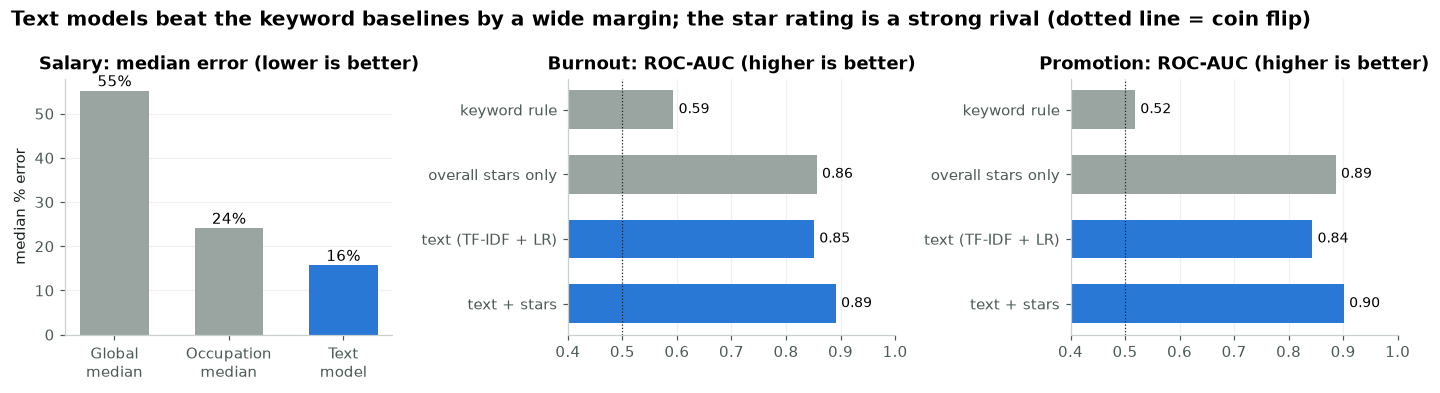

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
labels = ["Global\nmedian", "Occupation\nmedian", "Text\nmodel"]
vals = [s["baseline_global_median"]["MedAPE_%"], s["baseline_occupation_median"]["MedAPE_%"], s["ridge_text_model"]["MedAPE_%"]]
ax.bar(labels, vals, color=[GREY, GREY, BLUE], width=0.6)
for i, v in enumerate(vals): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=10)
ax.set_title("Salary: median error (lower is better)"); ax.set_ylabel("median % error"); ax.grid(axis="x")
for ax, key, title in [(axes[1], "burnout", "Burnout: ROC-AUC"), (axes[2], "promotion", "Promotion: ROC-AUC")]:
    t = cls_table(M[key]).dropna(subset=["ROC_AUC"])
    names = [n.split(": ")[1] for n in t.index]
    cols = [BLUE if n.startswith("Model") else GREY for n in t.index]
    ax.barh(names, t.ROC_AUC, color=cols, height=0.6); ax.set_xlim(0.4, 1); ax.axvline(0.5, color=INK, lw=0.8, ls=":")
    for i, v in enumerate(t.ROC_AUC): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
    ax.set_title(title + " (higher is better)"); ax.invert_yaxis(); ax.grid(axis="y")
fig.suptitle("Text models beat the keyword baselines by a wide margin; the star rating is a strong rival (dotted line = coin flip)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "model_vs_baselines.png", bbox_inches="tight"); plt.show()

**Reading the results**
* **Salary:** the text model cuts the typical error from ~24% (best baseline) to ~16%, and explains ~84% of the
  variation in log pay versus ~50%. The title and description carry real information about pay beyond the job family.
* **Burnout:** keyword matching ("toxic", "overworked"…) barely beats chance (AUC 0.59). The text model reaches ~0.85.
* **Promotion:** the word "promotion" appears in praise *and* complaints, so keywords are a coin flip (0.52).
  The text model reads context and reaches ~0.84.
* **An honest caveat:** the reviewer's *overall star rating* is a deliberately strong baseline. On its own it matches
  the burnout text model (0.86) and beats the promotion text model (0.89). Text + stars together is best on both
  (0.89 / 0.90). So why does the growth score use the text-only models? Because they measure burnout and promotion from
  what people *write*, a signal separate from the star ratings that already feed the score. Using star-based
  predictions would count the same ratings twice. The text models are also what let the calculator say *why*.

Words the burnout model learned push the prediction toward burnout:

In [8]:
print("burnout ↑ :", ", ".join(M["burnout"]["top_positive_terms"][:15]))
print("promotion ↑ :", ", ".join(M["promotion"]["top_positive_terms"][:15]))

burnout ↑ : no work, toxic, poor work, horrible, pros none, overworked, burnout, terrible, worst, cons work, awful, not good, not great, poor, not worth
promotion ↑ : great, growth cons, no cons, amazing, excellent, best, cons nothing, love, best company, awesome, incredible, supportive, pros career, outstanding, fantastic


## 4 · The growth score

For each occupation, seven components (your definition of growth):

| Component | Source |
|---|---|
| Salary | median posted pay; the salary model fills postings with no pay listed |
| Culture + diversity | mean of Glassdoor culture & values and diversity & inclusion ratings |
| Career opportunities | Glassdoor rating |
| Job openings | number of Indeed postings (log scale) |
| Promotion likelihood | promotion model, averaged over reviews |
| Work-life balance | Glassdoor rating |
| Burnout rate | burnout model, averaged over reviews (counts **against** the score) |

Each component becomes a percentile among the 44 occupations, and the growth score is the average × 100.
Two safeguards:
* **Small groups are pulled toward the overall average** (empirical Bayes, k = 20), so an occupation can't top the
  chart on a handful of glowing reviews. Occupations need ≥ 40 reviews and ≥ 40 postings.
* **200 bootstrap resamples** give a 90% interval for every score.

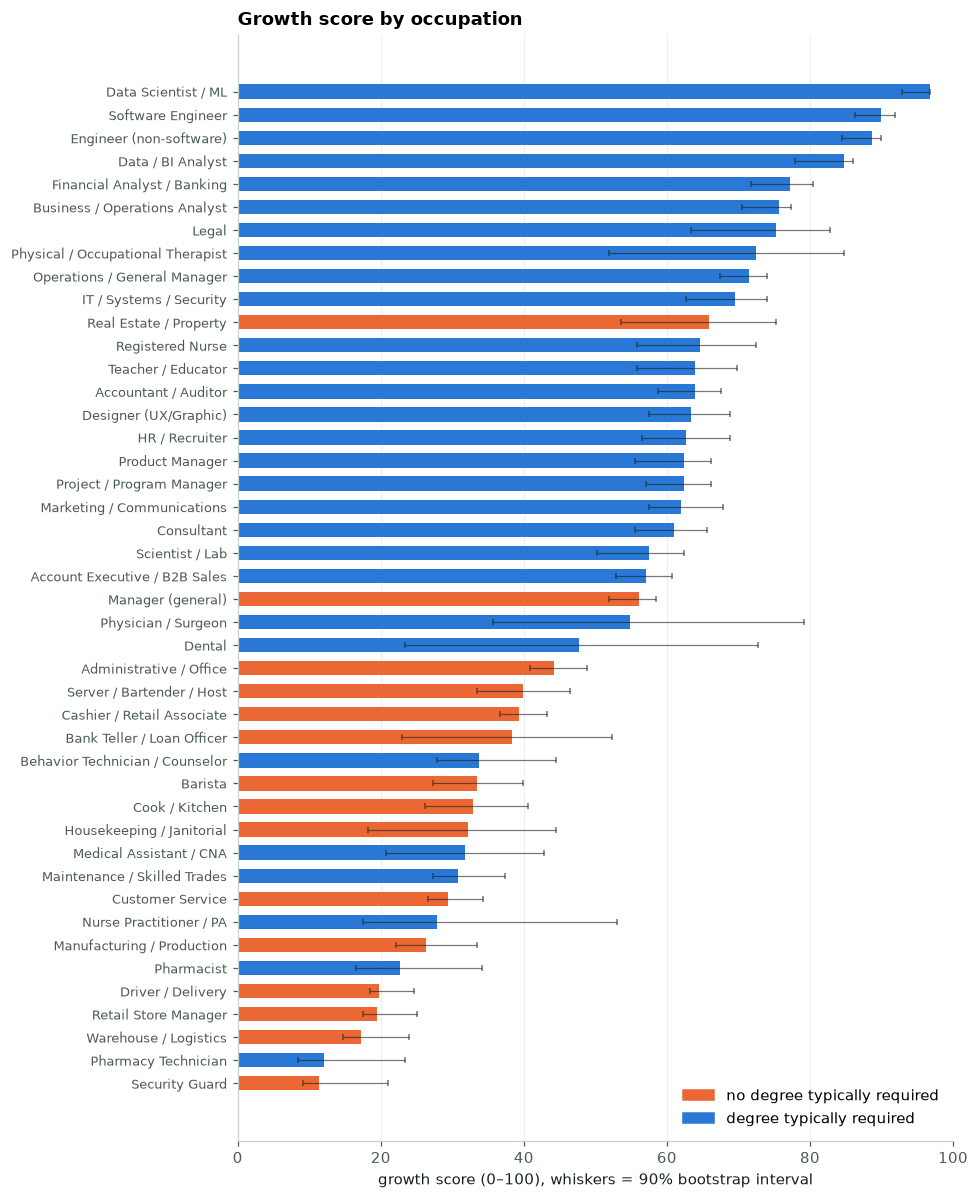

In [9]:
o = occ.sort_values("growth_score")
nod = o.typical_edu_years == 0
fig, ax = plt.subplots(figsize=(9, 11))
y = np.arange(len(o))
ax.barh(y, o.growth_score, color=np.where(nod, ORANGE, BLUE), height=0.62)
ax.errorbar(o.growth_score, y, xerr=[o.growth_score - o.score_ci_low, o.score_ci_high - o.growth_score],
            fmt="none", ecolor=INK, elinewidth=0.8, capsize=2, alpha=0.6)
ax.set_yticks(y, o.index, fontsize=8.5); ax.set_xlim(0, 100); ax.grid(axis="y")
ax.set_xlabel("growth score (0–100), whiskers = 90% bootstrap interval")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="no degree typically required"), Patch(color=BLUE, label="degree typically required")],
          loc="lower right", frameon=False)
ax.set_title("Growth score by occupation", loc="left")
fig.tight_layout(); fig.savefig(FIG / "growth_score_ranking.png", bbox_inches="tight"); plt.show()

## 5 · The story in four findings

In [10]:
o = occ.copy(); o["no_degree"] = o.typical_edu_years == 0
share_postings = o[o.no_degree].n_postings.sum() / o.n_postings.sum()
f1 = o.groupby("no_degree").growth_score.mean()
rho_h, p_h = spearmanr(o.share_hourly, o.growth_score)
rho_b, p_b = spearmanr(o.median_salary_model, o.burnout_rate)
rho_p, p_p = spearmanr(o.median_salary_model, o.promotion_likelihood)
print(f"1. No-degree occupations hold {share_postings:.0%} of postings but average a growth score of {f1[True]:.0f} vs {f1[False]:.0f}.")
print(f"2. Share of hourly postings vs growth score: Spearman rho = {rho_h:.2f} (p = {p_h:.1g}).")
print(f"3. Pay vs burnout rho = {rho_b:.2f} (p = {p_b:.1g}); pay vs promotion rho = {rho_p:.2f} (p = {p_p:.1g}).")
hp = o[(o.median_salary_model > 150_000) & (o.growth_score < 35)]
print("4. High pay, low growth:", ", ".join(f"{i} (${r.median_salary_model/1000:.0f}k, score {r.growth_score:.0f})" for i, r in hp.iterrows()))

1. No-degree occupations hold 36% of postings but average a growth score of 34 vs 60.
2. Share of hourly postings vs growth score: Spearman rho = -0.74 (p = 9e-09).
3. Pay vs burnout rho = -0.48 (p = 0.001); pay vs promotion rho = 0.63 (p = 5e-06).
4. High pay, low growth: Nurse Practitioner / PA ($168k, score 28), Pharmacist ($156k, score 23)


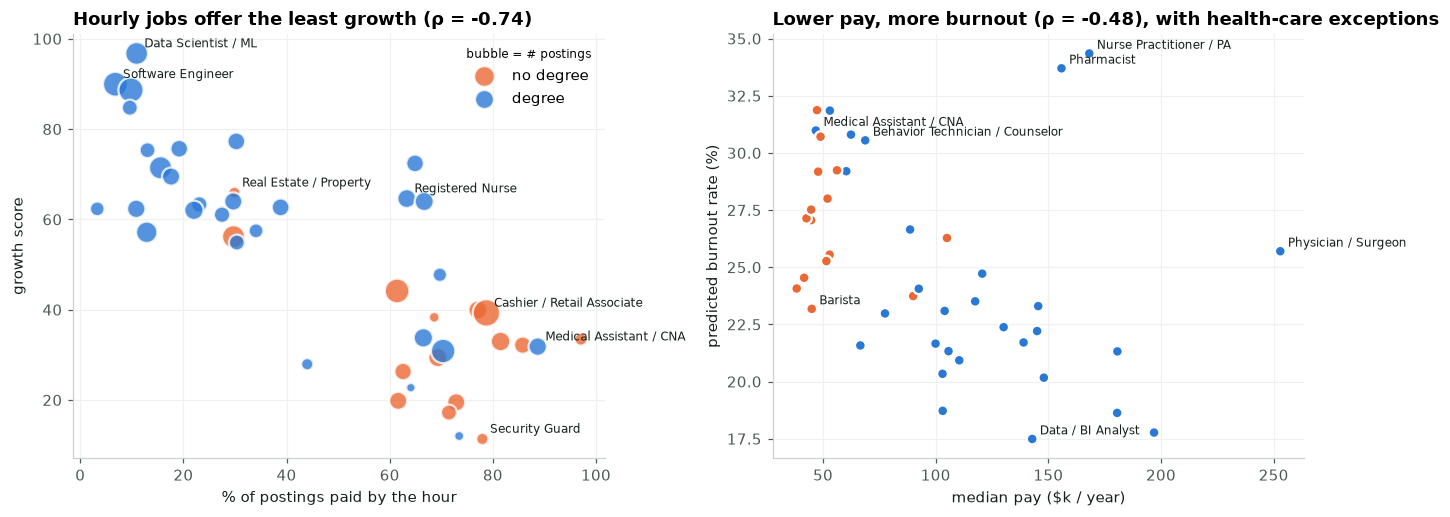

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for nd, col, lab in [(True, ORANGE, "no degree"), (False, BLUE, "degree")]:
    d = o[o.no_degree == nd]
    ax.scatter(d.share_hourly * 100, d.growth_score, s=np.sqrt(d.n_postings) * 3, color=col, alpha=0.8,
               edgecolor="white", linewidth=1.5, label=lab)
for name in ["Cashier / Retail Associate", "Software Engineer", "Registered Nurse", "Security Guard", "Real Estate / Property", "Data Scientist / ML", "Medical Assistant / CNA"]:
    r = o.loc[name]; ax.annotate(name, (r.share_hourly * 100, r.growth_score), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("% of postings paid by the hour"); ax.set_ylabel("growth score")
ax.set_title(f"Hourly jobs offer the least growth (ρ = {rho_h:.2f})", loc="left"); ax.legend(frameon=False, title="bubble = # postings", title_fontsize=8)
ax = axes[1]
ax.scatter(o.median_salary_model / 1000, o.burnout_rate * 100, s=50, color=np.where(o.no_degree, ORANGE, BLUE), edgecolor="white", linewidth=1.5)
for name in ["Pharmacist", "Nurse Practitioner / PA", "Medical Assistant / CNA", "Behavior Technician / Counselor", "Data / BI Analyst", "Barista", "Physician / Surgeon"]:
    r = o.loc[name]; ax.annotate(name, (r.median_salary_model / 1000, r.burnout_rate * 100), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("median pay ($k / year)"); ax.set_ylabel("predicted burnout rate (%)")
ax.set_title(f"Lower pay, more burnout (ρ = {rho_b:.2f}), with health-care exceptions", loc="left")
fig.tight_layout(); fig.savefig(FIG / "hourly_and_burnout.png", bbox_inches="tight"); plt.show()

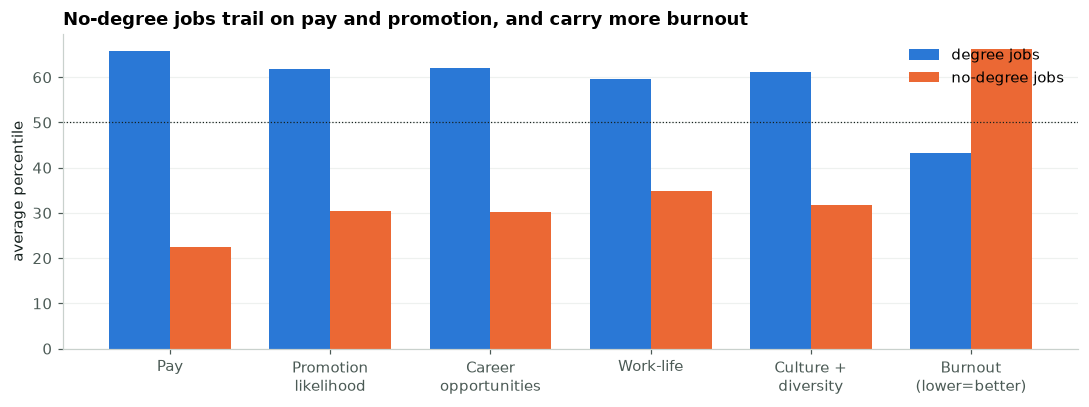

In [12]:
comp = ["median_salary_model", "promotion_likelihood", "career_opportunities", "work_life", "culture_diversity", "burnout_rate"]
names = ["Pay", "Promotion\nlikelihood", "Career\nopportunities", "Work-life", "Culture +\ndiversity", "Burnout\n(lower=better)"]
pct = o[comp].rank(pct=True) * 100
g = pct.groupby(o.no_degree).mean()
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(comp)); w = 0.38
ax.bar(x - w/2, g.loc[False], w, color=BLUE, label="degree jobs"); ax.bar(x + w/2, g.loc[True], w, color=ORANGE, label="no-degree jobs")
ax.axhline(50, color=INK, lw=0.8, ls=":"); ax.set_xticks(x, names); ax.set_ylabel("average percentile"); ax.grid(axis="x")
ax.set_title("No-degree jobs trail on pay and promotion, and carry more burnout", loc="left"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "degree_gap.png", bbox_inches="tight"); plt.show()

**What this means**
1. **The most accessible jobs are the least upwardly mobile.** No-degree occupations make up about a third of
   openings but score far lower, and the gap is widest on pay and promotion likelihood, the two things that turn
   a job into a career.
2. **Hourly pay is the clearest warning sign.** The share of hourly postings predicts a low growth score better than
   anything else we measured.
3. **Low-wage workers take a double hit:** less pay, *and* more burnout and fewer promotions. Disadvantages stack
   rather than trade off.
4. **High pay ≠ growth.** Pharmacists and nurse practitioners earn $155k+ but score low on burnout and work-life
   balance, so the score catches something salary rankings miss.
5. **There are ladders without degrees.** Real estate/property management and general management score near or
   above the middle with no degree typically required. Those are the paths worth pointing people toward.

### Financial ROI
`02b_roi.py` computes a 20-year net present value: occupation pay minus a no-degree baseline, less tuition and
earnings given up while studying. Typical entry education comes from a reference table (BLS-style), because posting
text rarely states it reliably. Assumptions: $27k/yr tuition, 3% discount rate.

In [13]:
roi = occ[["median_salary_model", "typical_edu_years", "education_cost", "npv_20yr_premium", "roi_multiple"]].sort_values("npv_20yr_premium", ascending=False)
print("no-degree baseline pay: $", M["roi_assumptions"]["no_degree_baseline_salary"])
roi.style.format({"median_salary_model": "${:,.0f}", "education_cost": "${:,.0f}", "npv_20yr_premium": "${:,.0f}", "roi_multiple": "{:.1f}×"}, na_rep="–")

no-degree baseline pay: $ 46800


,median_salary_model,typical_edu_years,education_cost,npv_20yr_premium,roi_multiple
occupation,,,,,
Product Manager,"$180,630",4,"$282,552","$1,255,852",4.4×
Software Engineer,"$180,500",4,"$282,552","$1,254,355",4.4×
Physician / Surgeon,"$252,931",8,"$533,595","$1,134,729",2.1×
IT / Systems / Security,"$139,000",2,"$145,450","$1,085,689",7.5×
Data Scientist / ML,"$196,900",6,"$411,782","$1,050,806",2.6×
Manager (general),"$105,000",0,$0,"$891,845",–
Engineer (non-software),"$147,996",4,"$282,552","$880,712",3.1×
Operations / General Manager,"$145,496",4,"$282,552","$851,978",3.0×
Legal,"$145,000",4,"$282,552","$846,276",3.0×


## 6 · Bias and limitations

### Who the models work worse for

,n,ROC_AUC,actual_rate,mean_pred,calibration_gap_pts
CONTRACT,605.0,0.862,0.203,0.226,2.3
INTERN,698.0,0.864,0.062,0.104,4.2
PART_TIME,2313.0,0.814,0.200,0.233,3.3
REGULAR,13375.0,0.853,0.275,0.267,-0.8


Salary model median % error by wage third: {'low': 14.9, 'middle': 16.0, 'high': 16.6}
Salary model median % error by pay type  : {'hourly': 14.9, 'salaried': 16.6}


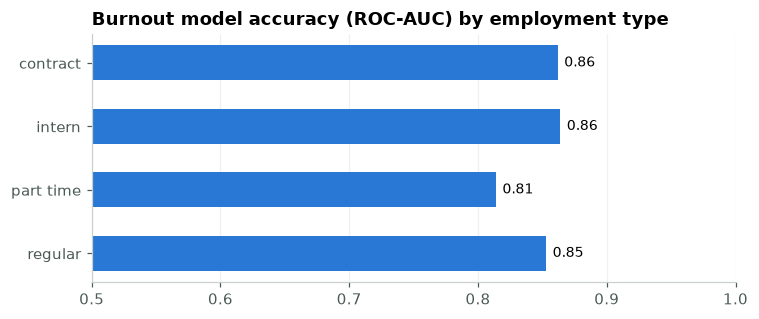

In [14]:
b = pd.DataFrame(M["burnout"]["by_employee_status"]).T
b["calibration_gap_pts"] = (b.mean_pred - b.actual_rate) * 100
display(b.round(3))
print("Salary model median % error by wage third:", s["by_wage_tier_MedAPE_%"])
print("Salary model median % error by pay type  :", s["by_pay_type_MedAPE_%"])
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(b.index.str.replace("_", " ").str.lower(), b.ROC_AUC, color=BLUE, height=0.55); ax.set_xlim(0.5, 1); ax.grid(axis="y")
for i, v in enumerate(b.ROC_AUC): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_title("Burnout model accuracy (ROC-AUC) by employment type", loc="left"); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "bias_by_status.png", bbox_inches="tight"); plt.show()

### How the data and model could hurt the communities studied

| Issue | Who it affects | What I did about it |
|---|---|---|
| **Who writes reviews.** Large tech/consulting firms are over-represented (Google alone ~4,000 reviews); hourly workers in food service, warehousing and care work post less. | Low-wage workers: their occupations rest on fewer, noisier voices. | Empirical-Bayes shrinkage; bootstrap intervals (wider whiskers on low-wage jobs show the uncertainty). |
| **Self-selection.** People with extreme experiences review more. | Everyone, unevenly. | Report intervals; the score is relative (percentiles), which is less sensitive to an overall shift. |
| **Pay transparency laws** mean postings with pay come mostly from CA, NY, WA, CO, IL. | Workers in lower-cost states see salaries that are too high. | State is a model feature; flagged in limitations. |
| **Hourly pay annualised at 2,080 h** assumes full-time work. | Part-time workers, mostly in retail, food and care. Their ROI is *overstated*. | Flagged; part-time share shown per occupation. |
| **Burnout is a proxy** (work-life rating ≤ 2). The model over-predicts burnout by 2–4 points for part-time, contract and intern reviewers (slightly under for regular employees) and discriminates worst for part-time workers. | Part-time workers' burnout estimates are least reliable. | Reported per-group AUC and calibration gap above. |
| **No demographics** in either dataset. | We can't test fairness by race, gender, age or disability; a high diversity rating can hide poor experiences for minority employees. | Stated plainly; recommend not using the score to screen people. |
| **English-only text models.** | Multilingual and immigrant workers' reviews get less reliable predictions. | Flagged. |
| **Rule-based title mapping** collapses seniority and misreads vague titles ("Associate"). | Occupations with vague titles (retail, warehouse). | 86% of postings / 82% of reviews map; unmapped rows excluded. |

**Responsible use:** the score should widen people's options, never steer first-generation or low-income students
*away* from fields. A low score for an occupation says nothing about a particular employer.

## 7 · From analysis to a tool: score any job posting

`growth_model.py build` packages the three models and the reference tables into a single JSON file
(`model/growth_model.json`). That same file powers the web **Growth Score Calculator**, so the notebook and the web
page give identical answers. Below, three example postings are scored with it.

In [15]:
if RUN_PIPELINE:
    run("growth_model.py", "build")   # ~5 min
from growth_model import GrowthScoreModel
gsm = GrowthScoreModel()
examples = [
    {"job_title": "Data Analyst", "company": "Kaiser Permanente", "state": "CA", "job_type": "Full-time",
     "description": "Analyze clinical and operational data with SQL and Python; build dashboards for leadership."},
    {"job_title": "Cashier", "company": "Walmart", "state": "TX", "job_type": "Part-time", "description": "Ring up customers, stock shelves."},
    {"job_title": "Property Manager", "company": "Greystar", "state": "IL", "job_type": "Full-time",
     "description": "Manage a 300-unit apartment community, leasing, budgets, resident relations."},
]
rows = []
for p in examples:
    r = gsm.score(p)
    rows.append({"job": p["job_title"], "company": p["company"], "growth_score": r["growth_score"], "occupation": r["occupation"],
                 "company_matched": r["company_matched"], "pay_used": round(r["values"]["salary"]),
                 **{k: round(v * 100) for k, v in r["percentiles"].items()}})
pd.DataFrame(rows)

salary (held-out companies): {'MedAPE_%': 15.8, 'MAE_$': 22587, 'R2_log': 0.83}
burnout_rate AUC 0.852
promotion_likelihood AUC 0.844
wrote /Users/janvi/Downloads/Datasets /job_roi_model/model/growth_model.json 1.11 MB; 44 occupations, 1765 companies
{
 "salary_model": {
  "MedAPE_%": 15.8,
  "MAE_$": 22587,
  "R2_log": 0.83
 },
 "burnout_rate_model_ROC_AUC": 0.852,
 "promotion_likelihood_model_ROC_AUC": 0.844,
 "json_vs_sklearn_max_rel_diff": 0.00032428885612427943,
 "score_check": {
  "n_held_out_postings": 400,
  "mean_abs_score_change_using_predicted_salary": 0.93,
  "share_within_5_points": 1.0,
  "share_company_matched": 0.297
 }
}
[growth_model.py finished in 59s]


,job,company,growth_score,occupation,company_matched,pay_used,salary,culture_diversity,career_opportunities,job_openings,promotion_likelihood,work_life,burnout_rate
0,Data Analyst,Kaiser Permanente,79.4,Data / BI Analyst,Kaiser Permanente,88226,45,100,100,31,100,89,91
1,Cashier,Walmart,33.3,Cashier / Retail Associate,Walmart,56100,32,2,39,99,14,9,39
2,Property Manager,Greystar,22.6,Real Estate / Property,Greystar,63890,39,0,61,8,45,5,0


In [16]:
gm = json.load(open(OUT / "growth_model_metrics.json"))
print(json.dumps(gm, indent=1))

{
 "salary_model": {
  "MedAPE_%": 15.8,
  "MAE_$": 22587,
  "R2_log": 0.83
 },
 "burnout_rate_model_ROC_AUC": 0.852,
 "promotion_likelihood_model_ROC_AUC": 0.844,
 "json_vs_sklearn_max_rel_diff": 0.00032428885612427943,
 "score_check": {
  "n_held_out_postings": 400,
  "mean_abs_score_change_using_predicted_salary": 0.93,
  "share_within_5_points": 1.0,
  "share_company_matched": 0.297
 }
}


## 8 · Conclusion and impact

**Answer to the question:** yes. Combining what employers offer with what employees say lets us predict a job's growth
potential, and the jobs most open to people without degrees offer the least of it. They pay less, burn people out
more, and promote less often.

**Impact:**
* **For job seekers,** especially first-generation and low-income workers: the calculator scores the specific posting
  they're considering in seconds and shows *why* (pay, promotion, burnout). It also highlights no-degree ladders like
  property and general management.
* **For workforce programs and counselors:** the occupation ranking shows where training dollars could move people from
  low-growth to higher-growth work.
* **For employers:** burnout and promotion signals read straight from reviews show what holds a job back.

**Next steps:** add demographic data (e.g. BLS CPS) for a real fairness audit; add Spanish-language text models; track
the same occupations over time to forecast growth directly instead of using a snapshot.